In [1]:
import scanpy as sc
import numpy as np
import scprep
from anndata import AnnData
import phate
from phate.cluster import kmeans
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [13]:
import sys
sys.path.append('..')
from dhg import Hypergraph
from hypgs.models.hsn_pyg import HSN
from hypgs.utils.data import HGDataset
from torch_geometric.loader import DataLoader
from torch_geometric.data import Dataset
import pytorch_lightning as pl
from pytorch_lightning.callbacks import EarlyStopping
from torch.utils.data import random_split
from pytorch_lightning.loggers import TensorBoardLogger
from hypgs import DATA_DIR
import anndata
import os
import torch
import numpy as np
import phate
from sklearn.neighbors import NearestNeighbors
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import euclidean_distances
import scanpy as sc
from sklearn.neighbors import kneighbors_graph
import random 
from torch_geometric.utils.convert import from_networkx


In [2]:
# datapath_mtg = '/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/data/SEA-AD/MTG/MERFISH/SEAAD_MTG_MERFISH_all-nuclei.2023-05-08.h5ad'
# # Load the file
# adata = sc.read_h5ad(datapath_mtg, backed='r')

In [3]:
# adata

In [4]:
# adata_donor = adata[adata.obs["Donor ID"] == 'H21.33.001']

In [5]:
# # PHATE
# phate_op = phate.PHATE(n_components=3)
# X_phate = phate_op.fit_transform(adata_donor.X)
# adata_donor.obsm['X_phate'] = X_phate

In [6]:
# adata_donor.copy(filename='merfish_donor_H21.33.001.h5ad')

In [2]:
adata_donor = sc.read_h5ad('merfish_donor_H21.33.001.h5ad', backed='r')

In [3]:
(adata_donor.obsm['X_spatial_raw'] == adata_donor.obsm['spatial']).all()

True

<Figure size 5000x4000 with 0 Axes>

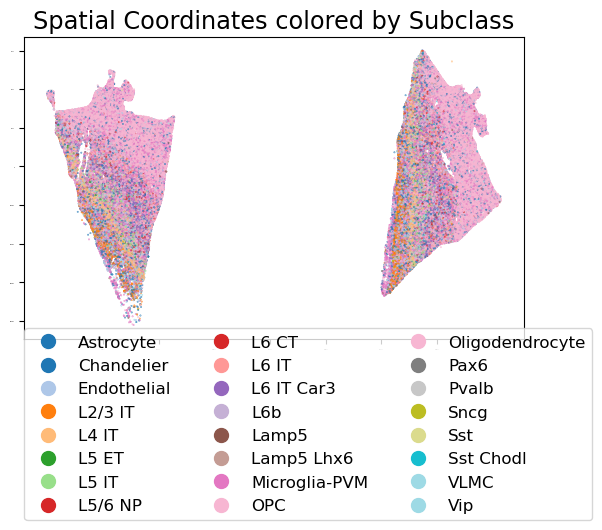

In [77]:
fig = plt.figure(figsize=(50, 40))
ax = scprep.plot.scatter2d(adata_donor.obsm['X_spatial_tiled'], s=.1, c=adata_donor.obs['Subclass'], cmap='tab20', legend_loc=(0, -.6), title=f'Spatial Coordinates colored by Subclass')
ax.tick_params(axis='x', labelsize=0)
ax.tick_params(axis='y', labelsize=0)
plt.tight_layout()
plt.show()

Subsample cells

In [5]:
np.random.seed(42)
subset_idx = np.random.choice(adata_donor.shape[0], 10000, replace=False)
adata_donor_subset = adata_donor[subset_idx, :].copy(filename='merfish_donor_H21.33.001_subset.h5ad')

<Figure size 5000x4000 with 0 Axes>

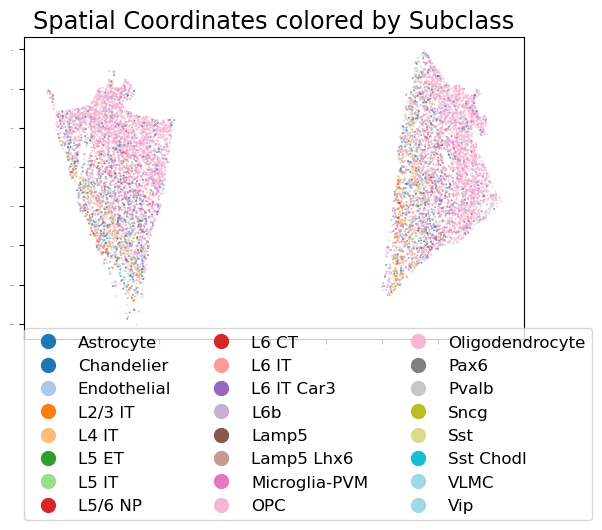

In [78]:
fig = plt.figure(figsize=(50, 40))
ax = scprep.plot.scatter2d(adata_donor_subset.obsm['X_spatial_tiled'], s=.1, c=adata_donor_subset.obs['Subclass'], cmap='tab20', legend_loc=(0, -.6), title=f'Spatial Coordinates colored by Subclass')
ax.tick_params(axis='x', labelsize=0)
ax.tick_params(axis='y', labelsize=0)
plt.tight_layout()
plt.show()

In [11]:
# PHATE
phate_op = phate.PHATE(n_components=3)
X_phate = phate_op.fit_transform(adata_donor_subset[:,:].X)
adata_donor_subset.obsm['X_phate'] = X_phate

Calculating PHATE...
  Running PHATE on 10000 observations and 180 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.53 seconds.
    Calculating KNN search...


    Calculated KNN search in 12.57 seconds.
    Calculating affinities...
    Calculated affinities in 3.19 seconds.
  Calculated graph and diffusion operator in 16.34 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 2.57 seconds.
    Calculating KMeans...
    Calculated KMeans in 15.71 seconds.
  Calculated landmark operator in 21.31 seconds.
  Calculating optimal t...
    Automatically selected t = 9
  Calculated optimal t in 9.80 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 6.69 seconds.
  Calculating metric MDS...


/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/sklearn/manifold/_mds.py:299: FutureWarning: The default value of `normalized_stress` will change to `'auto'` in version 1.4. To suppress this warning, manually set the value of `normalized_stress`.
  warnings.warn(


  Calculated metric MDS in 203.30 seconds.
Calculated PHATE in 257.49 seconds.


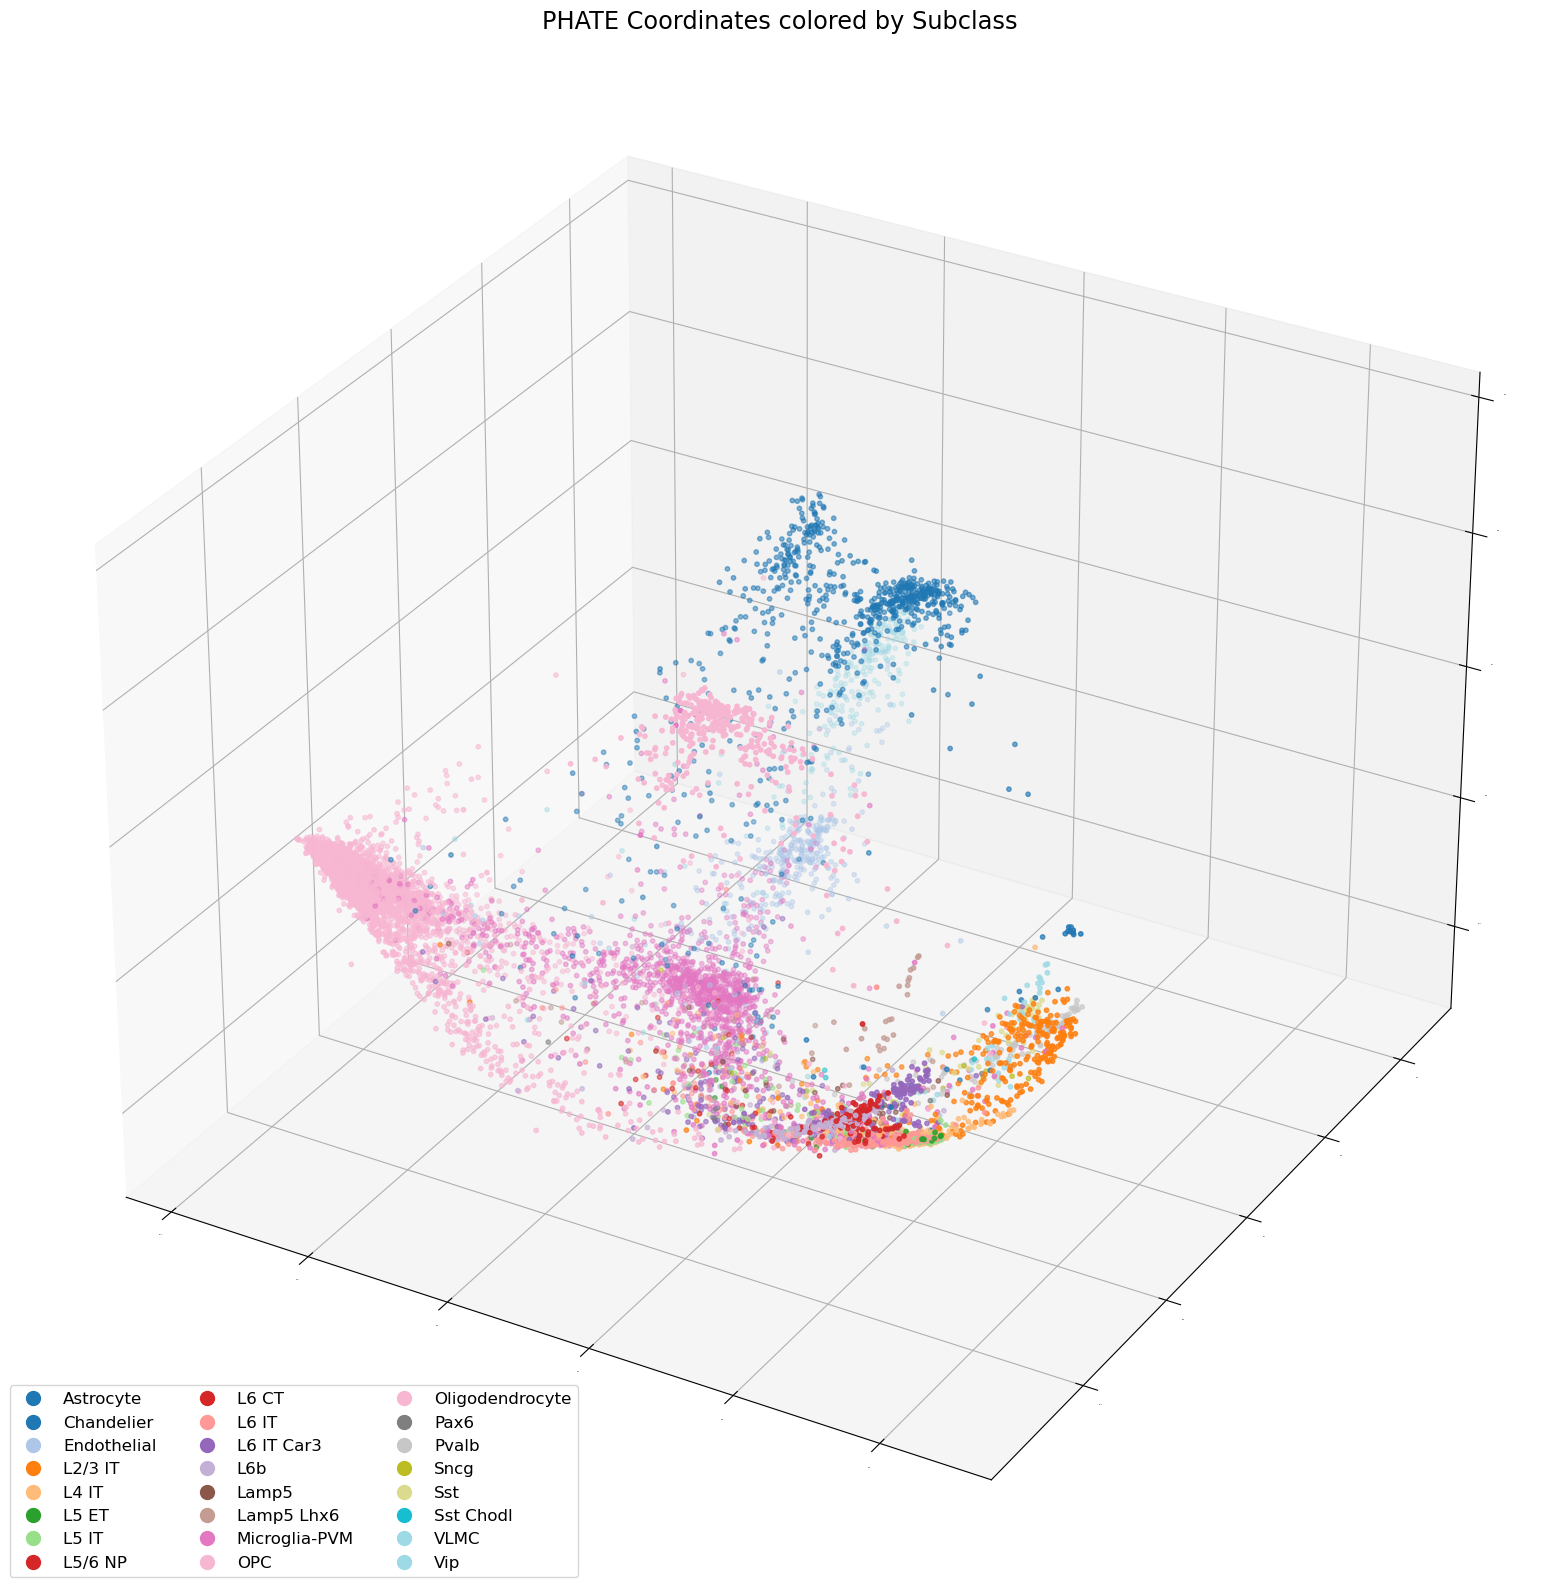

In [12]:
fig = plt.figure(figsize=(20, 20), dpi=100)
ax = fig.add_subplot(111, projection='3d')
scprep.plot.scatter3d(adata_donor_subset.obsm['X_phate'] , s=10, c=adata_donor_subset.obs['Subclass'], cmap='tab20', legend_loc=(0, 0), title=f'PHATE Coordinates colored by Subclass', ax=ax)
ax.tick_params(axis='x', labelsize=0)
ax.tick_params(axis='y', labelsize=0)
ax.tick_params(axis='z', labelsize=0)
# plt.tight_layout()
plt.show()

In [79]:
K=10
sparseA = kneighbors_graph(adata_donor_subset.obsm['X_spatial_tiled'], K, mode='connectivity', include_self=False)
A = sparseA.todense()
G = nx.from_numpy_array(A)

In [17]:
# PHATE
phate10_op = phate.PHATE(n_components=10)
X_phate10 = phate10_op.fit_transform(adata_donor_subset[:,:].X)
adata_donor_subset.obsm['X_phate10'] = X_phate10

Calculating PHATE...
  Running PHATE on 10000 observations and 180 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 1.18 seconds.
    Calculating KNN search...
    Calculated KNN search in 33.72 seconds.
    Calculating affinities...
    Calculated affinities in 2.95 seconds.
  Calculated graph and diffusion operator in 37.89 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 1.11 seconds.
    Calculating KMeans...
    Calculated KMeans in 11.20 seconds.
  Calculated landmark operator in 13.87 seconds.
  Calculating optimal t...
    Automatically selected t = 9
  Calculated optimal t in 5.73 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 5.16 seconds.
  Calculating metric MDS...


/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/sklearn/manifold/_mds.py:299: FutureWarning: The default value of `normalized_stress` will change to `'auto'` in version 1.4. To suppress this warning, manually set the value of `normalized_stress`.
  warnings.warn(


  Calculated metric MDS in 304.34 seconds.
Calculated PHATE in 367.01 seconds.


In [33]:
from importlib import reload
from hypgs.models.hsn_pyg import HyperScatteringModule

In [80]:
from torch_geometric.utils.convert import from_networkx
data = from_networkx(G)
data.x = torch.tensor(X_phate)
original_dataset = [data]
to_hg_func = lambda g: Hypergraph.from_graph_kHop(g, 1)
dataset = HGDataset(original_dataset, to_hg_func)

Converting to hypergraph data: 100%|██████████| 1/1 [00:37<00:00, 37.94s/it]


In [81]:
model = HyperScatteringModule(in_channels=10, 
              trainable_laziness = False,
              trainable_scales = False, 
              activation = None, # just get one layer of wavelet transform 
              fixed_weights=True, 
              normalize='right', 
        )

In [82]:
out_features = model(dataset[0].x.float(), dataset[0].edge_index, hyperedge_attr = dataset[0].edge_attr)

In [83]:
node_feat = out_features[0][:, 0]

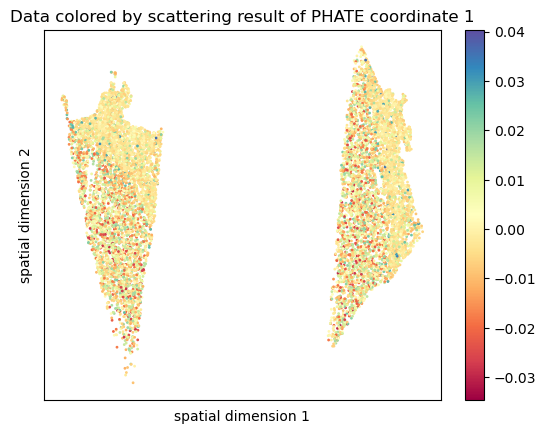

In [84]:
plt.scatter(adata_donor_subset.obsm['X_spatial_tiled'][:,0], 
            adata_donor_subset.obsm['X_spatial_tiled'][:,1], 
            c = node_feat.detach().numpy(), s=1, cmap='Spectral')
plt.xlabel('spatial dimension 1')
plt.ylabel('spatial dimension 2')
plt.xticks([])
plt.yticks([])
plt.colorbar()
plt.title('Data colored by scattering result of PHATE coordinate 1')
plt.show()

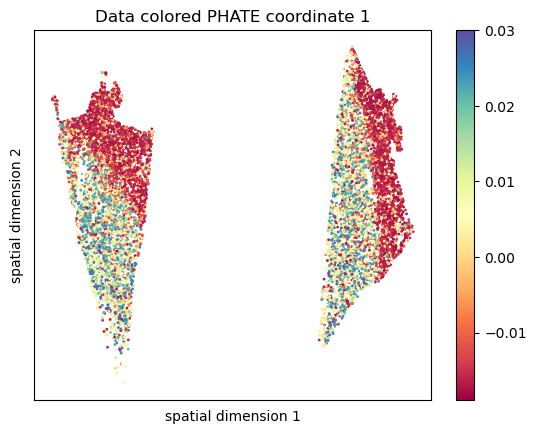

In [85]:
plt.scatter(adata_donor_subset.obsm['X_spatial_tiled'][:,0], 
            adata_donor_subset.obsm['X_spatial_tiled'][:,1], 
            c = X_phate10[:, 0], s=1, cmap='Spectral')
plt.xlabel('spatial dimension 1')
plt.ylabel('spatial dimension 2')
plt.xticks([])
plt.yticks([])
plt.colorbar()
plt.title('Data colored PHATE coordinate 1')
plt.show()

In [60]:
node_feat_old = node_feat.cpu().detach().numpy()

In [68]:
node_feat

tensor([ 0.0077, -0.0040, -0.0026,  ..., -0.0119,  0.0218,  0.0197],
       grad_fn=<SelectBackward0>)

In [69]:
node_feat_old

array([ 0.00848305, -0.00504894, -0.0029831 , ..., -0.01182907,
        0.01997549,  0.0180825 ], dtype=float32)

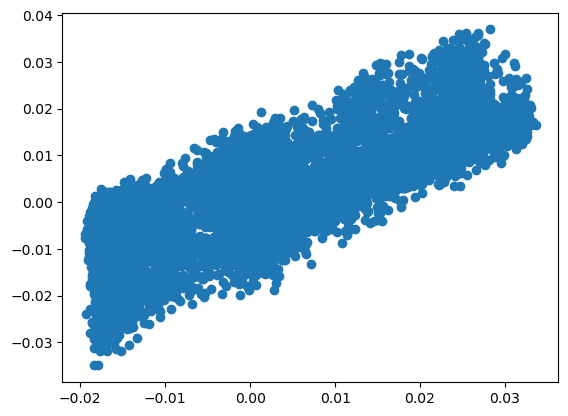

In [71]:
plt.scatter(X_phate[:, 0], node_feat.detach().numpy())

<Figure size 5000x4000 with 0 Axes>

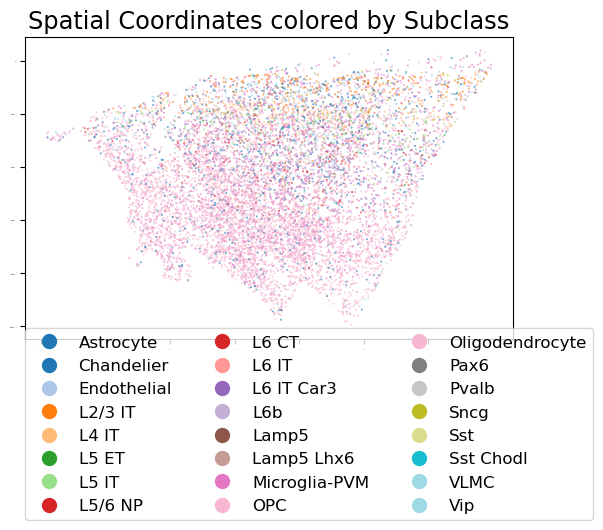

In [75]:
fig = plt.figure(figsize=(50, 40))
ax = scprep.plot.scatter2d(adata_donor_subset.obsm['X_selected_cell_spatial_tiled'], s=.1, c=adata_donor_subset.obs['Subclass'], cmap='tab20', legend_loc=(0, -.6), title=f'Spatial Coordinates colored by Subclass')
ax.tick_params(axis='x', labelsize=0)
ax.tick_params(axis='y', labelsize=0)
plt.tight_layout()
plt.show()

<Figure size 5000x4000 with 0 Axes>

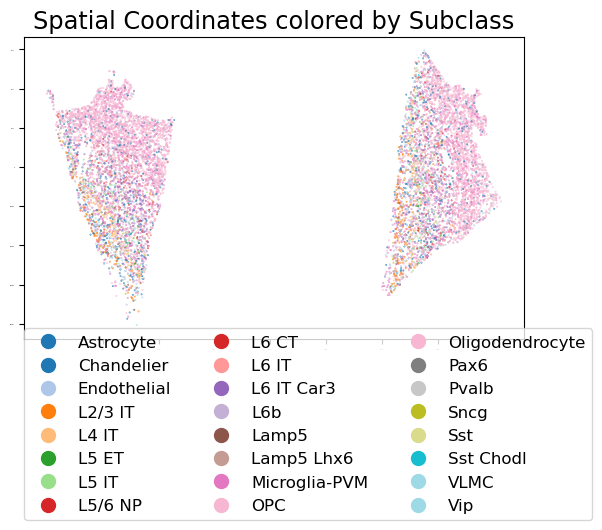

In [76]:
fig = plt.figure(figsize=(50, 40))
ax = scprep.plot.scatter2d(adata_donor_subset.obsm['X_spatial_tiled'], s=.1, c=adata_donor_subset.obs['Subclass'], cmap='tab20', legend_loc=(0, -.6), title=f'Spatial Coordinates colored by Subclass')
ax.tick_params(axis='x', labelsize=0)
ax.tick_params(axis='y', labelsize=0)
plt.tight_layout()
plt.show()

In [89]:
adata_donor_subset.obs["Used in analysis"].mean()

0.1871

In [96]:
adata_donor_subset.obsm["X_selected_cell_spatial_tiled"]

(10000, 2)

In [102]:
fig = plt.figure(figsize=(50, 40))
ax = scprep.plot.scatter2d(adata_donor_subset.obsm['X_selected_cell_spatial_tiled'].iloc[np.where(adata_donor_subset.obs["Used in analysis"]), :], s=.1, c=adata_donor_subset.obs['Subclass'], cmap='tab20', legend_loc=(0, -.6), title=f'Spatial Coordinates colored by Subclass')
ax.tick_params(axis='x', labelsize=0)
ax.tick_params(axis='y', labelsize=0)
plt.tight_layout()
plt.show()

AttributeError: 'numpy.ndarray' object has no attribute 'iloc'

<Figure size 5000x4000 with 0 Axes>

In [98]:
adata_donor_subset.obs["Used in analysis"]

0.1871